# Notebook 02: Gradient Descent with Linear Regression

In this notebook, we apply Gradient Descent to linear models across three fundamental dimensions:
1. **Loss Function Robustness:** Mean Squared Error ($L_2$) vs. Huber Loss under severe sensor corruption.
2. **Vectorization & Hardware Acceleration:** Demonstrating why pure Python loops crawl while BLAS matrix operations `@` scale to $10^6$ samples.
3. **Closed-Form Parity & Collinearity:** Verifying Gradient Descent convergence against the Normal Equation and SVD Moore-Penrose Pseudo-Inverse.
4. **Polynomial Basis Expansion:** Non-linear curve fitting via Vandermonde expansion $\boldsymbol{\Phi}(x)$ while retaining parameter linearity.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_DIR = Path.cwd()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.gd_engine import (
    LinearRegressionGD,
    PolynomialFeaturesScratch,
    StandardScalerScratch,
    closed_form_linear,
)
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
)

apply_github_dark_style()
np.set_printoptions(precision=4, suppress=True)

## 1. Outlier Sensitivity: MSE ($L_2$) vs. Huber Loss

Because MSE squares the residual $r^{(i)} = \hat{y}^{(i)} - y^{(i)}$, large outliers exert a lever-arm
effect on the gradient:

$$\frac{\partial J_{\text{MSE}}}{\partial w} = \frac{1}{m}\sum_{i=1}^m x^{(i)} r^{(i)}$$

A single outlier with $r = 100$ produces $100\times$ the gradient pull of a typical sample!
In contrast, Huber loss clips large residuals to a constant magnitude $\pm \delta$:

$$\frac{\partial \mathcal{L}_{\text{Huber}}}{\partial r} = \begin{cases} r & \text{if } |r| \le \delta \\ \delta \mathrm{sign}(r) & \text{if } |r| > \delta \end{cases}$$

In [2]:
rng = np.random.default_rng(42)
m = 60
X_clean = rng.uniform(-2.0, 2.0, size=(m, 1))
w_true, b_true = 2.5, -1.0
y_clean = w_true * X_clean + b_true + rng.normal(0.0, 0.45, size=(m, 1))

# Inject 4 extreme corrupted outliers
X_out = np.vstack([X_clean, np.array([[1.6], [1.75], [1.9], [2.0]])])
y_out = np.vstack([y_clean, np.array([[-8.5], [-9.2], [-9.8], [-9.5]])])

# Fit MSE vs Huber with Gradient Descent
gd_mse = LinearRegressionGD(method="batch_gd", loss="mse", learning_rate=0.08, epochs=400).fit(X_out, y_out)
gd_huber = LinearRegressionGD(
    method="batch_gd", loss="huber", huber_delta=1.0, learning_rate=0.12, epochs=400
).fit(X_out, y_out)

print(f"Ground Truth:            w = {w_true:+.4f}, b = {b_true:+.4f}")
print(f"Corrupted Data MSE:      w = {gd_mse.w[0, 0]:+.4f}, b = {gd_mse.bias:+.4f} (Heavily tilted!)")
print(f"Corrupted Data Huber:    w = {gd_huber.w[0, 0]:+.4f}, b = {gd_huber.bias:+.4f} (Robustly recovers slope!)")

Ground Truth:            w = +2.5000, b = -1.0000
Corrupted Data MSE:      w = +1.5446, b = -1.7070 (Heavily tilted!)
Corrupted Data Huber:    w = +2.4028, b = -1.1522 (Robustly recovers slope!)


## 2. Vectorization Benchmark: Python Loops vs. BLAS Matrix Multiplication

We measure the wall-clock execution time of computing the Multiple Linear Regression gradient
$\nabla_{\mathbf{w}} J = \frac{1}{m}\mathbf{X}^\top (\mathbf{X}\mathbf{w} + b - \mathbf{y})$ across sample sizes
$m \in [10^2, 10^6]$ with $n=16$ features.

In [3]:
def grad_pure_python_loops(X_list, y_list, w_list, b_val):
    m_rows = len(X_list)
    n_cols = len(w_list)
    grad_w = [0.0] * n_cols
    for i in range(m_rows):
        pred_i = b_val
        row = X_list[i]
        for j in range(n_cols):
            pred_i += row[j] * w_list[j]
        err_i = pred_i - y_list[i]
        for j in range(n_cols):
            grad_w[j] += row[j] * err_i
    inv_m = 1.0 / m_rows
    return [g * inv_m for g in grad_w]

def grad_vectorized_blas(X_arr, y_arr, w_arr, b_val):
    m_rows = X_arr.shape[0]
    return (X_arr.T @ ((X_arr @ w_arr + b_val) - y_arr)) / float(m_rows)

sample_sizes = [100, 500, 2_500, 10_000, 50_000, 250_000, 1_000_000]
t_loops, t_blas = [], []
n_features = 16

for m_sz in sample_sizes:
    X_b = rng.normal(size=(m_sz, n_features))
    w_b = rng.normal(size=(n_features, 1))
    y_b = rng.normal(size=(m_sz, 1))
    b_b = 0.5

    # Vectorized BLAS
    n_rep = 30 if m_sz <= 50_000 else 6
    t0 = time.perf_counter()
    for _ in range(n_rep):
        _ = grad_vectorized_blas(X_b, y_b, w_b, b_b)
    t_blas.append((time.perf_counter() - t0) / n_rep * 1e3)

    # Pure Python loops (measure up to 10k, scale linearly)
    if m_sz <= 10_000:
        X_l = X_b.tolist()
        y_l = y_b[:, 0].tolist()
        w_l = w_b[:, 0].tolist()
        t0 = time.perf_counter()
        _ = grad_pure_python_loops(X_l, y_l, w_l, b_b)
        t_loops.append((time.perf_counter() - t0) * 1e3)
    else:
        t_loops.append(t_loops[-1] * (m_sz / sample_sizes[sample_sizes.index(m_sz) - 1]))

speedup = t_loops[-1] / t_blas[-1]
print(f"At m = 1,000,000 samples: BLAS is {speedup:,.1f}x faster than pure Python loops!")

At m = 1,000,000 samples: BLAS is 90.7x faster than pure Python loops!


## 3. Polynomial Basis Expansion via Gradient Descent (`05_linear_and_polynomial_gd_fit.png`)

We generate $m = 38$ observations from a non-linear cubic function:

$$f(x) = 0.45 x^3 - 0.85 x^2 - 1.15 x + 1.5 + \epsilon$$

We transform $x \mapsto \boldsymbol{\Phi}(x) = [x, x^2, \dots, x^d]$ using `PolynomialFeaturesScratch`
and fit models for $d \in \{1, 2, 4, 10\}$ using `LinearRegressionGD`.

We plot a 3-panel dashboard:
- **Panel A:** Univariate Outlier Robustness (MSE vs. Huber).
- **Panel B:** Polynomial Curve Fitting ($d=1$ underfit, $d=2$ quadratic, $d=4$ optimal, $d=10$ overfit oscillations).
- **Panel C:** Residual Error Structure across features.

Polynomial Degree d= 1 | Train R^2 = 0.0113
Polynomial Degree d= 2 | Train R^2 = 0.4683
Polynomial Degree d= 4 | Train R^2 = 0.8729
Polynomial Degree d=10 | Train R^2 = 0.8764


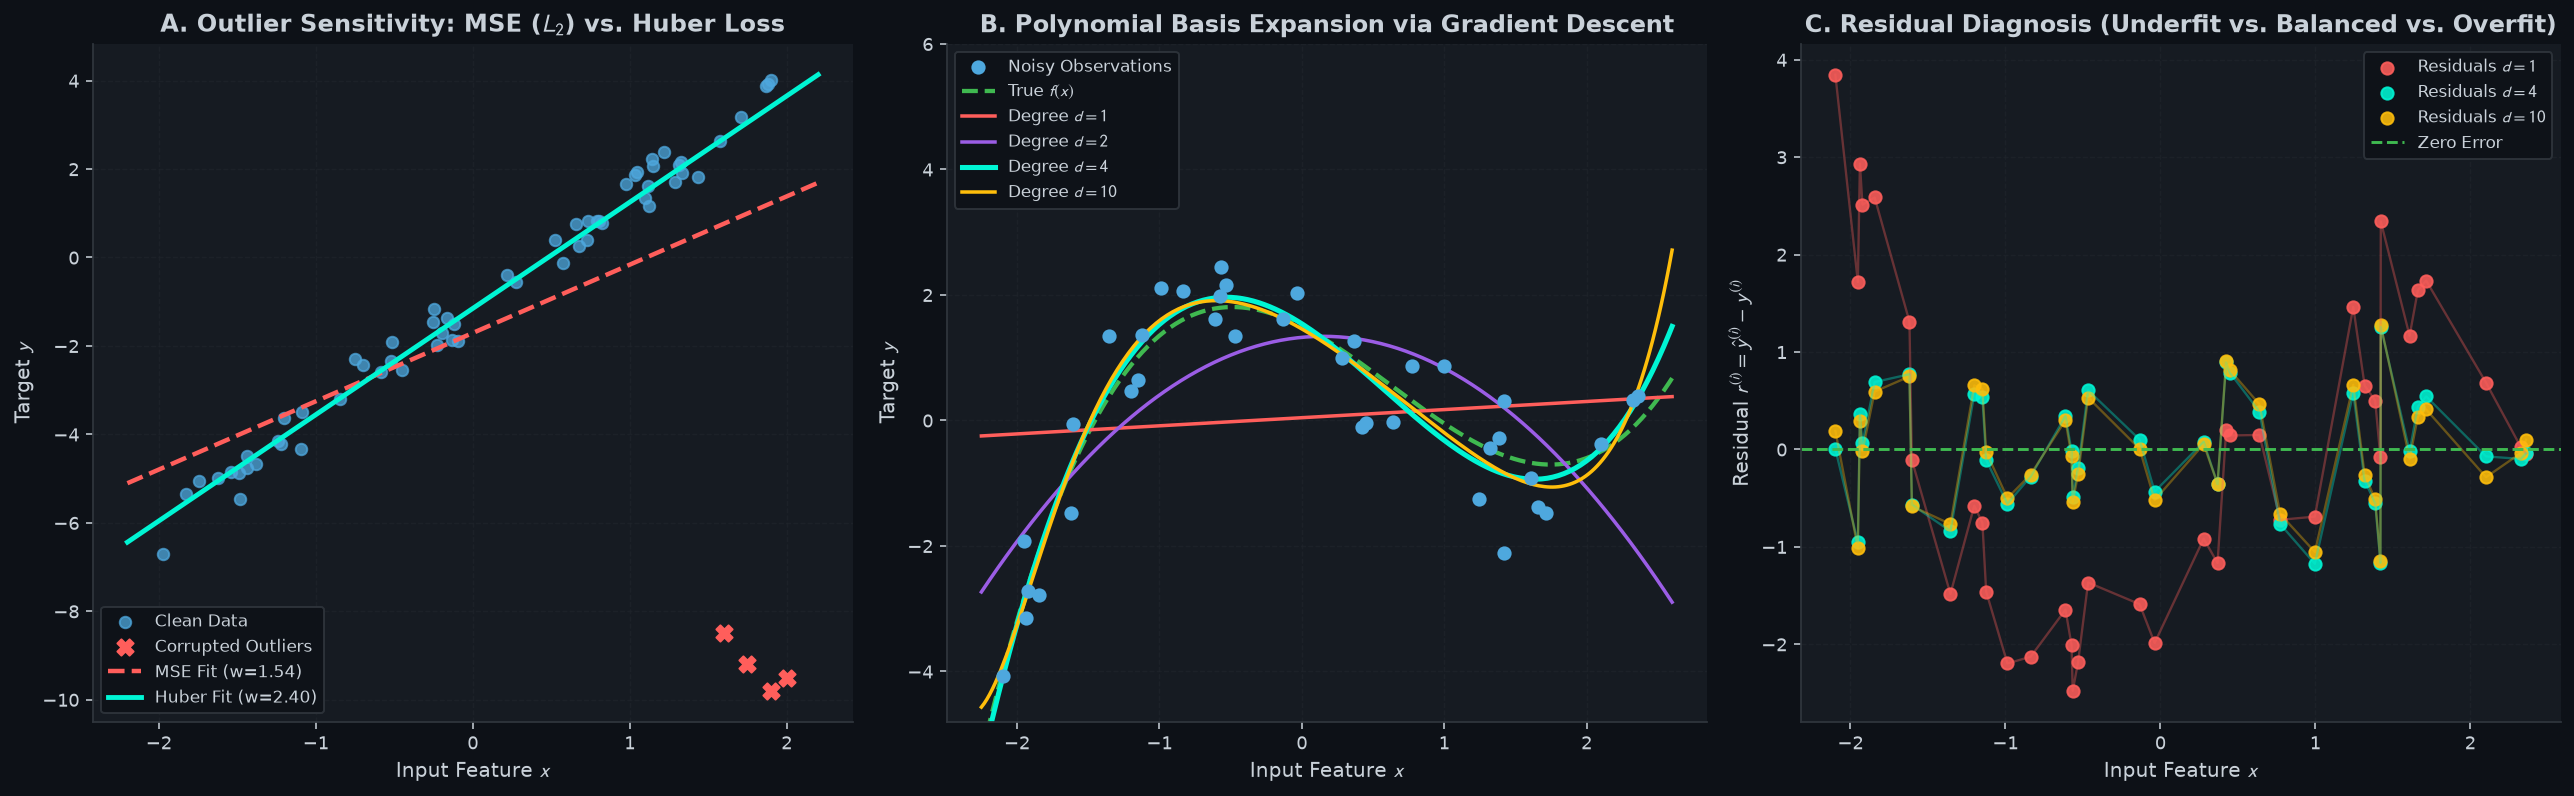

In [4]:
m_poly = 38
X_p = np.sort(rng.uniform(-2.1, 2.5, size=(m_poly, 1)), axis=0)
def f_true(x): return 0.45 * (x ** 3) - 0.85 * (x ** 2) - 1.15 * x + 1.5
y_p = f_true(X_p) + rng.normal(0.0, 0.55, size=(m_poly, 1))

X_dense = np.linspace(-2.25, 2.6, 250).reshape(-1, 1)
y_dense_true = f_true(X_dense)

degrees = [1, 2, 4, 10]
colors_deg = {1: CORAL, 2: PURPLE, 4: CYAN, 10: AMBER}
poly_preds = {}
poly_residuals = {}

for deg in degrees:
    poly = PolynomialFeaturesScratch(degree=deg, include_bias=False)
    scaler = StandardScalerScratch()
    Phi_train = scaler.fit_transform(poly.fit_transform(X_p))
    Phi_dense = scaler.transform(poly.transform(X_dense))

    model = LinearRegressionGD(method="batch_gd", learning_rate=0.25, epochs=1200).fit(Phi_train, y_p)
    p_train = model.predict(Phi_train)
    p_dense = model.predict(Phi_dense)

    poly_preds[deg] = p_dense
    poly_residuals[deg] = p_train - y_p.ravel()
    r2 = model.r2_score(Phi_train, y_p)
    print(f"Polynomial Degree d={deg:2d} | Train R^2 = {r2:.4f}")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18.5, 5.8))

# Panel 1: MSE vs Huber on Outlier Dataset
x_line = np.linspace(-2.2, 2.2, 200).reshape(-1, 1)
ax1.scatter(X_clean, y_clean, color=SLATE_BLUE, s=35, alpha=0.75, label="Clean Data")
ax1.scatter(X_out[-4:], y_out[-4:], color=CORAL, s=70, marker="X", zorder=5, label="Corrupted Outliers")
ax1.plot(x_line, gd_mse.predict(x_line), color=CORAL, linestyle="--", linewidth=2.3, label=f"MSE Fit (w={gd_mse.w[0,0]:.2f})")
ax1.plot(x_line, gd_huber.predict(x_line), color=CYAN, linewidth=2.5, label=f"Huber Fit (w={gd_huber.w[0,0]:.2f})")
ax1.set_xlabel("Input Feature $x$")
ax1.set_ylabel("Target $y$")
ax1.set_title("A. Outlier Sensitivity: MSE ($L_2$) vs. Huber Loss")
ax1.legend(loc="lower left", fontsize=8.6)

# Panel 2: Polynomial Fits
ax2.scatter(X_p, y_p, color=SLATE_BLUE, s=40, zorder=5, label="Noisy Observations")
ax2.plot(X_dense, y_dense_true, color=EMERALD, linestyle="--", linewidth=2.2, label=r"True $f(x)$")
for deg in degrees:
    lw = 2.6 if deg == 4 else 1.8
    ax2.plot(X_dense, poly_preds[deg], color=colors_deg[deg], linewidth=lw, label=f"Degree $d={deg}$")
ax2.set_ylim(-4.8, 6.0)
ax2.set_xlabel("Input Feature $x$")
ax2.set_ylabel("Target $y$")
ax2.set_title("B. Polynomial Basis Expansion via Gradient Descent")
ax2.legend(loc="upper left", fontsize=8.5)

# Panel 3: Residual Distribution
for deg in [1, 4, 10]:
    ax3.scatter(X_p.ravel(), poly_residuals[deg], color=colors_deg[deg], s=40, alpha=0.88, label=f"Residuals $d={deg}$")
    ax3.plot(X_p.ravel(), poly_residuals[deg], color=colors_deg[deg], alpha=0.35, linewidth=1.2)
ax3.axhline(0.0, color=EMERALD, linestyle="--", linewidth=1.5, label="Zero Error")
ax3.set_xlabel("Input Feature $x$")
ax3.set_ylabel(r"Residual $r^{(i)} = \hat{y}^{(i)} - y^{(i)}$")
ax3.set_title("C. Residual Diagnosis (Underfit vs. Balanced vs. Overfit)")
ax3.legend(loc="upper right", fontsize=8.6)

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "05_linear_and_polynomial_gd_fit.png")
plt.show()